# Visualizaciones: redes neuronales y Deep Learning

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import os

OUT = '.'
os.makedirs(OUT, exist_ok=True)
np.random.seed(42)

DARK_BG  = '#0d1117'
PANEL_BG = '#161b22'
BLUE     = '#388bfd'
ORANGE   = '#f0883e'
GREEN    = '#56d364'
RED      = '#ff7b72'
PURPLE   = '#bc8cff'
GRAY     = '#8b949e'
WHITE    = '#e6edf3'

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.facecolor': PANEL_BG, 'figure.facecolor': DARK_BG,
                     'axes.labelcolor': WHITE, 'xtick.color': GRAY, 'ytick.color': GRAY,
                     'text.color': WHITE, 'axes.edgecolor': '#30363d', 'grid.color': '#21262d'})
print('Setup OK')

Setup OK


## Gráfico 1 — Estructura de una Red Neuronal (FNN)

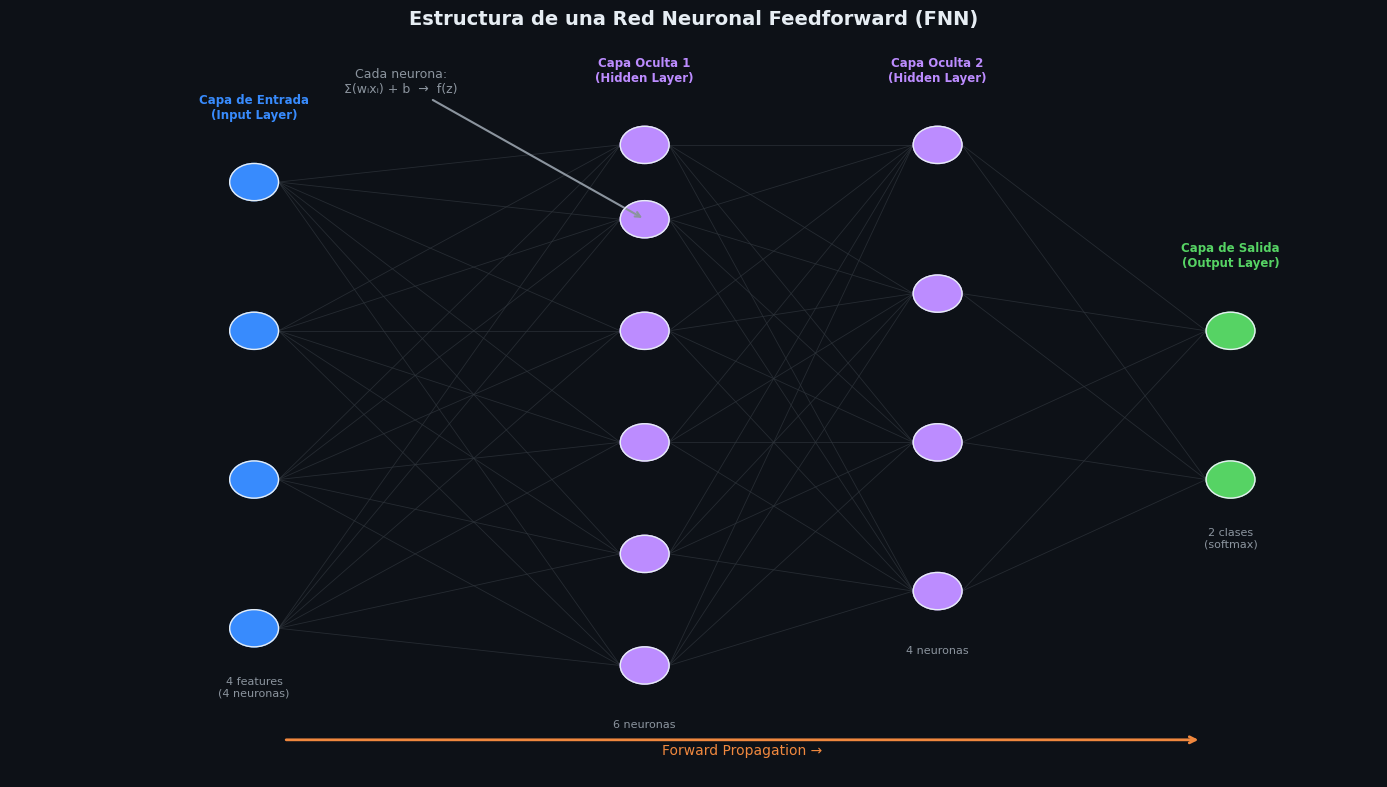

Guardado: 01_red_neuronal_estructura.png


In [2]:
fig, ax = plt.subplots(figsize=(14, 8))
ax.set_xlim(-1, 13)
ax.set_ylim(-1, 9)
ax.axis('off')
ax.set_title('Estructura de una Red Neuronal Feedforward (FNN)', color=WHITE, fontsize=14, fontweight='bold')

layers = [
    ('Capa de Entrada\n(Input Layer)', [1, 3, 5, 7], 1.5, BLUE, '4 features\n(4 neuronas)'),
    ('Capa Oculta 1\n(Hidden Layer)', [0.5, 2, 3.5, 5, 6.5, 7.5], 5.5, PURPLE, '6 neuronas'),
    ('Capa Oculta 2\n(Hidden Layer)', [1.5, 3.5, 5.5, 7.5], 8.5, PURPLE, '4 neuronas'),
    ('Capa de Salida\n(Output Layer)', [3, 5], 11.5, GREEN, '2 clases\n(softmax)'),
]

layer_neurons = [[1,3,5,7], [0.5,2,3.5,5,6.5,7.5], [1.5,3.5,5.5,7.5], [3,5]]
layer_xs = [1.5, 5.5, 8.5, 11.5]
layer_colors = [BLUE, PURPLE, PURPLE, GREEN]

# Draw connections
for l in range(len(layer_neurons)-1):
    for y1 in layer_neurons[l]:
        for y2 in layer_neurons[l+1]:
            ax.plot([layer_xs[l]+0.25, layer_xs[l+1]-0.25], [y1, y2],
                   color='#30363d', linewidth=0.6, alpha=0.7, zorder=1)

# Draw neurons
for (title, ys, x, color, subtitle) in layers:
    for y in ys:
        circle = plt.Circle((x, y), 0.25, color=color, zorder=3)
        ax.add_patch(circle)
        circle_edge = plt.Circle((x, y), 0.25, color=WHITE, fill=False, linewidth=1, zorder=4)
        ax.add_patch(circle_edge)
    ax.text(x, max(ys)+1.0, title, ha='center', va='center', color=color, fontsize=8.5, fontweight='bold')
    ax.text(x, min(ys)-0.8, subtitle, ha='center', va='center', color=GRAY, fontsize=8)

# Neuron detail annotation
ax.annotate('Cada neurona:\nΣ(wᵢxᵢ) + b  →  f(z)', 
           xy=(5.5, 6.5), xytext=(3, 8.2),
           arrowprops=dict(arrowstyle='->', color=GRAY, lw=1.5),
           color=GRAY, fontsize=9, ha='center')

# Forward arrow
ax.annotate('', xy=(11.2, -0.5), xytext=(1.8, -0.5),
   arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2))
ax.text(6.5, -0.7, 'Forward Propagation →', ha='center', color=ORANGE, fontsize=10)

plt.tight_layout()
plt.savefig(f'{OUT}/01_red_neuronal_estructura.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 01_red_neuronal_estructura.png')

## Gráfico 2 — Funciones de activación comparadas

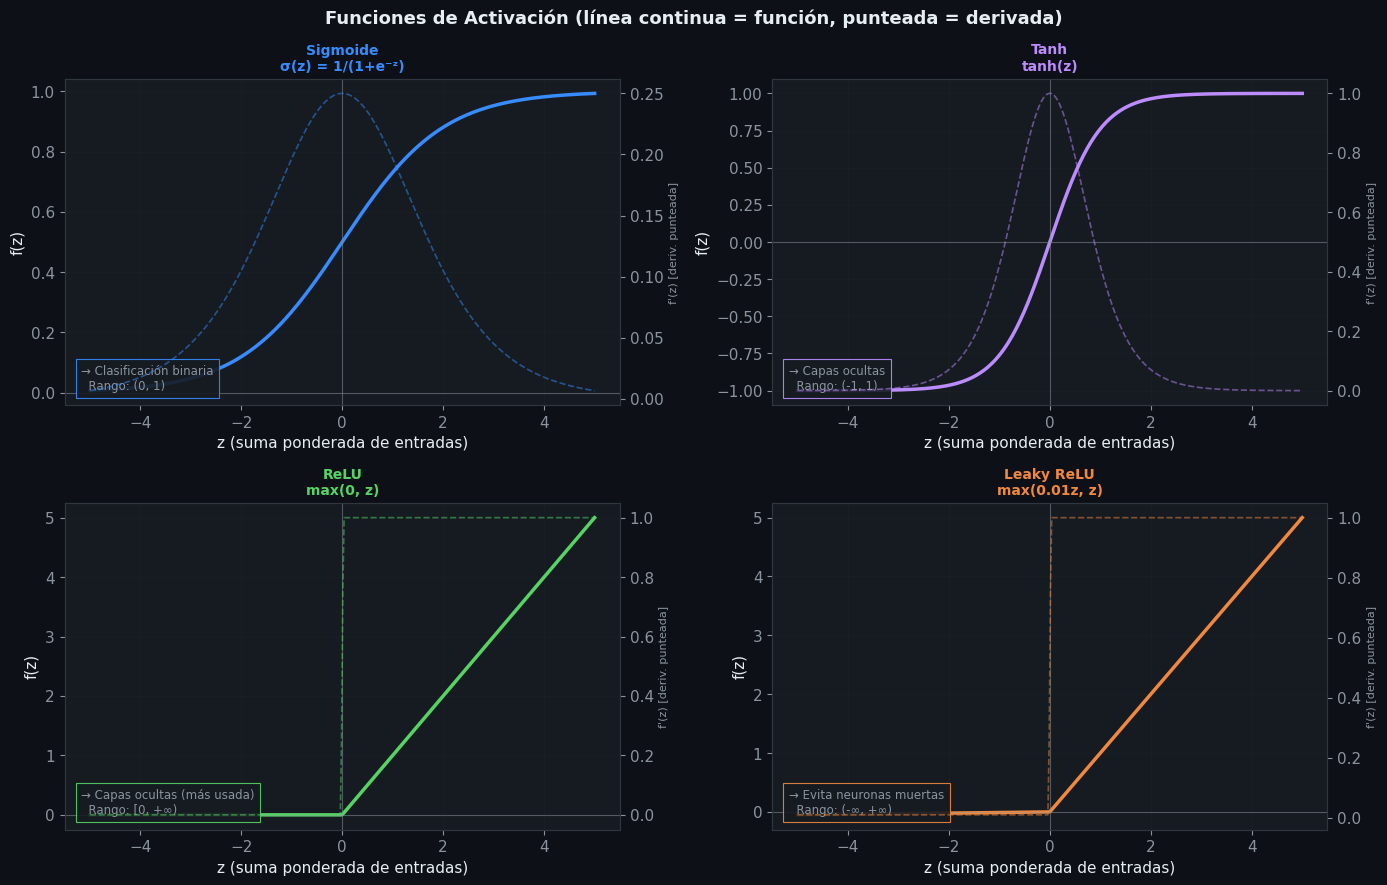

Guardado: 02_funciones_activacion.png


In [3]:
z = np.linspace(-5, 5, 400)

activations = [
    ('Sigmoide\nσ(z) = 1/(1+e⁻ᶻ)',  1/(1+np.exp(-z)),  BLUE,   '→ Clasificación binaria\n  Rango: (0, 1)'),
    ('Tanh\ntanh(z)',                  np.tanh(z),        PURPLE, '→ Capas ocultas\n  Rango: (-1, 1)'),
    ('ReLU\nmax(0, z)',                np.maximum(0, z),  GREEN,  '→ Capas ocultas (más usada)\n  Rango: [0, +∞)'),
    ('Leaky ReLU\nmax(0.01z, z)',      np.where(z>=0, z, 0.01*z), ORANGE, '→ Evita neuronas muertas\n  Rango: (-∞, +∞)'),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, (name, vals, color, desc) in zip(axes, activations):
    ax.plot(z, vals, color=color, linewidth=2.5)
    ax.axhline(0, color=GRAY, linewidth=0.8, linestyle='-', alpha=0.5)
    ax.axvline(0, color=GRAY, linewidth=0.8, linestyle='-', alpha=0.5)
    
    # Derivative
    dz = np.gradient(vals, z)
    ax2 = ax.twinx()
    ax2.plot(z, dz, color=color, linewidth=1.2, linestyle='--', alpha=0.5)
    ax2.set_ylabel("f'(z) [deriv. punteada]", color=GRAY, fontsize=8)
    ax2.tick_params(colors=GRAY)
    ax2.set_facecolor(PANEL_BG)
    
    ax.set_title(name, color=color, fontweight='bold', fontsize=10)
    ax.set_xlabel('z (suma ponderada de entradas)')
    ax.set_ylabel('f(z)')
    ax.grid(True, alpha=0.3)
    ax.text(0.03, 0.05, desc, transform=ax.transAxes, color=GRAY, fontsize=8.5,
           bbox=dict(facecolor=PANEL_BG, edgecolor=color, linewidth=0.8, alpha=0.9))

plt.suptitle('Funciones de Activación (línea continua = función, punteada = derivada)', 
            color=WHITE, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/02_funciones_activacion.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 02_funciones_activacion.png')

## Gráfico 3 — Gradient Descent paso a paso

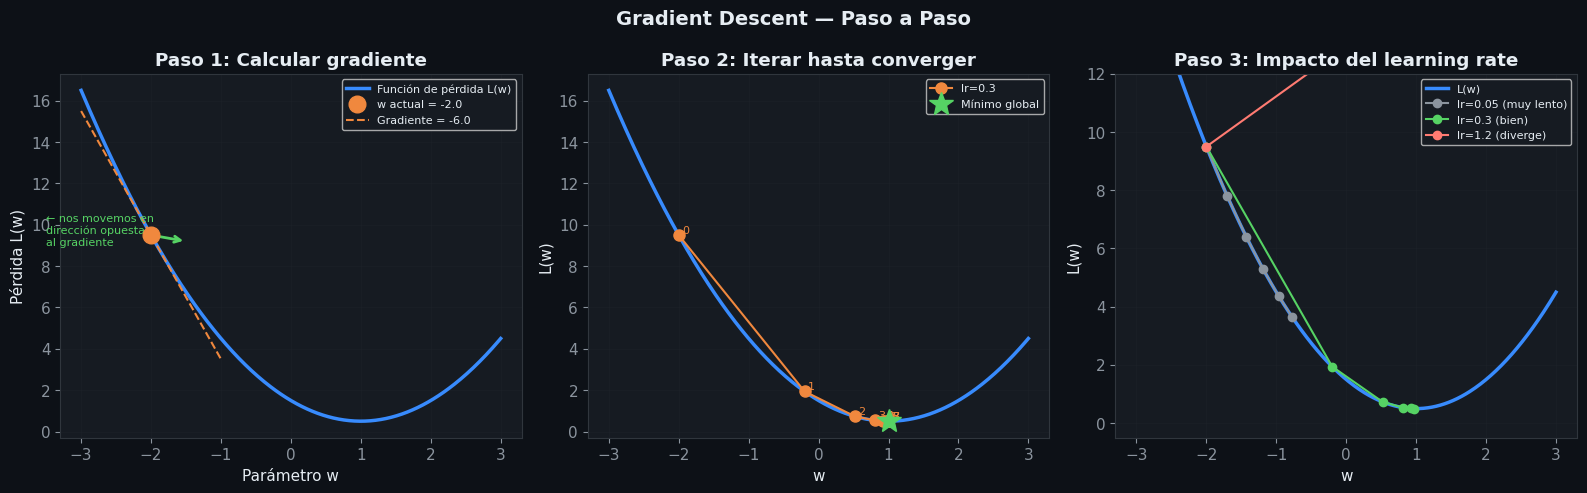

Guardado: 03_gradient_descent.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Loss landscape
w = np.linspace(-3, 3, 400)
loss = (w - 1)**2 + 0.3*np.sin(5*w) + 0.5  # non-convex
loss_simple = (w - 1)**2 + 0.5              # convex

# Step 1: gradient concept
ax = axes[0]
ax.plot(w, loss_simple, color=BLUE, linewidth=2.5, label='Función de pérdida L(w)')
w0 = -2.0
grad0 = 2*(w0 - 1)
ax.plot(w0, (w0-1)**2+0.5, 'o', color=ORANGE, markersize=12, zorder=5, label=f'w actual = {w0}')
# Tangent line
w_tang = np.linspace(w0-1, w0+1, 100)
ax.plot(w_tang, (w0-1)**2+0.5 + grad0*(w_tang - w0), color=ORANGE, linewidth=1.5, linestyle='--', label=f'Gradiente = {grad0:.1f}')
ax.annotate('', xy=(w0 - 0.5*np.sign(grad0), (w0-1)**2+0.5 - 0.3),
           xytext=(w0, (w0-1)**2+0.5),
           arrowprops=dict(arrowstyle='->', color=GREEN, lw=2))
ax.text(w0-1.5, (w0-1)**2+0.5-0.5, '← nos movemos en\ndirección opuesta\nal gradiente', color=GREEN, fontsize=8)
ax.set_title('Paso 1: Calcular gradiente', color=WHITE, fontweight='bold')
ax.set_xlabel('Parámetro w')
ax.set_ylabel('Pérdida L(w)')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
ax.grid(True, alpha=0.3)

# Step 2: iterations of gradient descent
ax = axes[1]
ax.plot(w, loss_simple, color=BLUE, linewidth=2.5)
lr = 0.3
w_cur = -2.0
traj_w = [w_cur]
traj_l = [(w_cur-1)**2+0.5]
for _ in range(8):
    grad = 2*(w_cur - 1)
    w_cur = w_cur - lr * grad
    traj_w.append(w_cur)
    traj_l.append((w_cur-1)**2+0.5)

ax.plot(traj_w, traj_l, 'o-', color=ORANGE, markersize=8, linewidth=1.5, zorder=4, label=f'lr={lr}')
for i, (tw, tl) in enumerate(zip(traj_w, traj_l)):
    ax.text(tw+0.05, tl+0.1, str(i), color=ORANGE, fontsize=8)
ax.plot(1, 0.5, '*', color=GREEN, markersize=18, zorder=5, label='Mínimo global')
ax.set_title('Paso 2: Iterar hasta converger', color=WHITE, fontweight='bold')
ax.set_xlabel('w')
ax.set_ylabel('L(w)')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
ax.grid(True, alpha=0.3)

# Step 3: learning rate effect
ax = axes[2]
ax.plot(w, loss_simple, color=BLUE, linewidth=2.5, label='L(w)')

for lr, color, label in [(0.05, GRAY, 'lr=0.05 (muy lento)'), (0.3, GREEN, 'lr=0.3 (bien)'), (1.2, RED, 'lr=1.2 (diverge)')]:
    w_cur = -2.0
    tw = [w_cur]
    tl = [(w_cur-1)**2+0.5]
    for _ in range(8):
        grad = 2*(w_cur - 1)
        w_cur = w_cur - lr * grad
        tw.append(min(max(w_cur, -3), 3))
        tl.append(min((w_cur-1)**2+0.5, 20))
    ax.plot(tw[:6], tl[:6], 'o-', color=color, markersize=6, linewidth=1.5, label=label)

ax.set_title('Paso 3: Impacto del learning rate', color=WHITE, fontweight='bold')
ax.set_xlabel('w')
ax.set_ylabel('L(w)')
ax.set_ylim(-0.5, 12)
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
ax.grid(True, alpha=0.3)

plt.suptitle('Gradient Descent — Paso a Paso', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/03_gradient_descent.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 03_gradient_descent.png')

## Gráfico 4 — Problemas de entrenamiento (vanishing/exploding gradient, dropout)

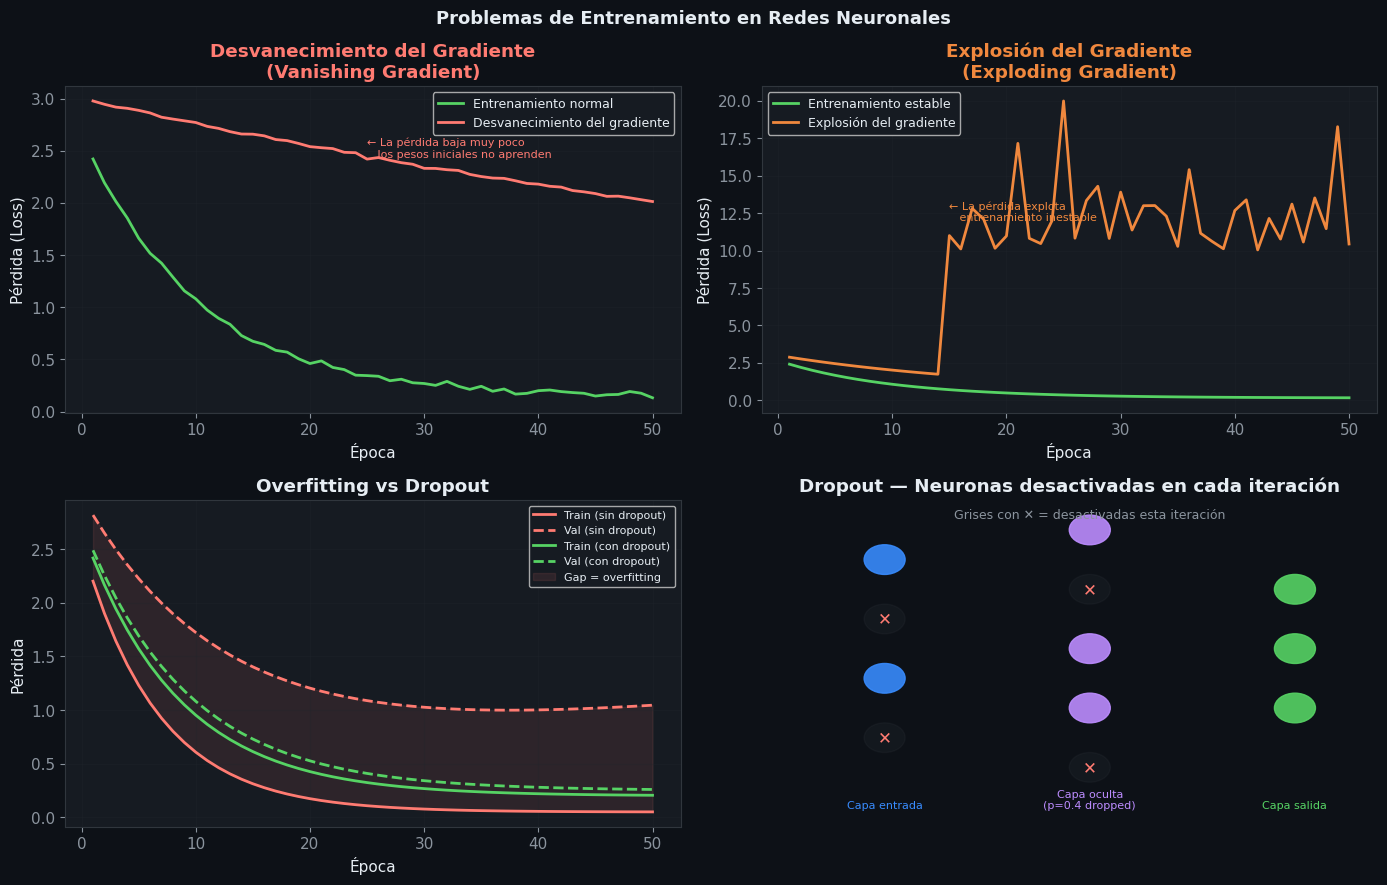

Guardado: 04_problemas_entrenamiento.png


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

epochs = np.arange(1, 51)

# 1: Vanishing gradient
ax = axes[0]
normal_loss = 2.5 * np.exp(-0.1 * epochs) + 0.15 + np.random.normal(0, 0.02, 50)
vanishing_loss = 2.5 * np.exp(-0.01 * epochs) + 0.5 + np.random.normal(0, 0.01, 50)
ax.plot(epochs, normal_loss, color=GREEN, linewidth=2, label='Entrenamiento normal')
ax.plot(epochs, vanishing_loss, color=RED, linewidth=2, label='Desvanecimiento del gradiente')
ax.set_title('Desvanecimiento del Gradiente\n(Vanishing Gradient)', color=RED, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('Pérdida (Loss)')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=9)
ax.text(25, vanishing_loss[25], '← La pérdida baja muy poco\n   los pesos iniciales no aprenden', 
       color=RED, fontsize=8)
ax.grid(True, alpha=0.3)

# 2: Exploding gradient
ax = axes[1]
stable_loss = 2.5 * np.exp(-0.1 * epochs) + 0.15
exploding = np.where(epochs < 15, 2.5*np.exp(-0.05*epochs)+0.5, 10 + np.random.exponential(3, 50))
exploding = np.clip(exploding, 0, 20)
ax.plot(epochs, stable_loss, color=GREEN, linewidth=2, label='Entrenamiento estable')
ax.plot(epochs, exploding, color=ORANGE, linewidth=2, label='Explosión del gradiente')
ax.set_title('Explosión del Gradiente\n(Exploding Gradient)', color=ORANGE, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('Pérdida (Loss)')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=9)
ax.text(15, 12, '← La pérdida explota\n   entrenamiento inestable', color=ORANGE, fontsize=8)
ax.grid(True, alpha=0.3)

# 3: Overfitting vs Dropout
ax = axes[2]
train_loss_overfit = 2.5 * np.exp(-0.15 * epochs) + 0.05
val_loss_overfit   = 2.5 * np.exp(-0.08 * epochs) + 0.5 + 0.01 * epochs
train_loss_dropout = 2.5 * np.exp(-0.12 * epochs) + 0.2
val_loss_dropout   = 2.5 * np.exp(-0.11 * epochs) + 0.25

ax.plot(epochs, train_loss_overfit, color=RED, linewidth=2, linestyle='-', label='Train (sin dropout)')
ax.plot(epochs, val_loss_overfit, color=RED, linewidth=2, linestyle='--', label='Val (sin dropout)')
ax.plot(epochs, train_loss_dropout, color=GREEN, linewidth=2, linestyle='-', label='Train (con dropout)')
ax.plot(epochs, val_loss_dropout, color=GREEN, linewidth=2, linestyle='--', label='Val (con dropout)')
ax.fill_between(epochs, train_loss_overfit, val_loss_overfit, alpha=0.1, color=RED, label='Gap = overfitting')
ax.set_title('Overfitting vs Dropout', color=WHITE, fontweight='bold')
ax.set_xlabel('Época')
ax.set_ylabel('Pérdida')
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, fontsize=8)
ax.grid(True, alpha=0.3)

# 4: Dropout visualization
ax = axes[3]
ax.set_xlim(-0.5, 7)
ax.set_ylim(-0.5, 5)
ax.axis('off')
ax.set_title('Dropout — Neuronas desactivadas en cada iteración', color=WHITE, fontweight='bold')

layer_pos = [1, 3.5, 6]
layer_neurons_vis = [[1,2,3,4], [0.5,1.5,2.5,3.5,4.5], [1.5,2.5,3.5]]
# dropped = random 40%
dropped = {1: [1,3], 3.5: [0.5, 3.5]}

for lx, ys in zip(layer_pos, layer_neurons_vis):
    for y in ys:
        is_dropped = y in dropped.get(lx, [])
        color = '#30363d' if is_dropped else (BLUE if lx==1 else PURPLE if lx==3.5 else GREEN)
        alpha = 0.2 if is_dropped else 0.9
        c = plt.Circle((lx, y), 0.25, color=color, alpha=alpha, zorder=3)
        ax.add_patch(c)
        if is_dropped:
            ax.text(lx, y, '✕', ha='center', va='center', color=RED, fontsize=12, fontweight='bold', zorder=4)

ax.text(1, -0.2, 'Capa entrada', ha='center', color=BLUE, fontsize=8)
ax.text(3.5, -0.2, 'Capa oculta\n(p=0.4 dropped)', ha='center', color=PURPLE, fontsize=8)
ax.text(6, -0.2, 'Capa salida', ha='center', color=GREEN, fontsize=8)
ax.text(3.5, 4.7, 'Grises con ✕ = desactivadas esta iteración', ha='center', color=GRAY, fontsize=9)

plt.suptitle('Problemas de Entrenamiento en Redes Neuronales', color=WHITE, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/04_problemas_entrenamiento.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 04_problemas_entrenamiento.png')

## Gráfico 5 — Tipos de redes neuronales (FNN, CNN, RNN, Autoencoder)

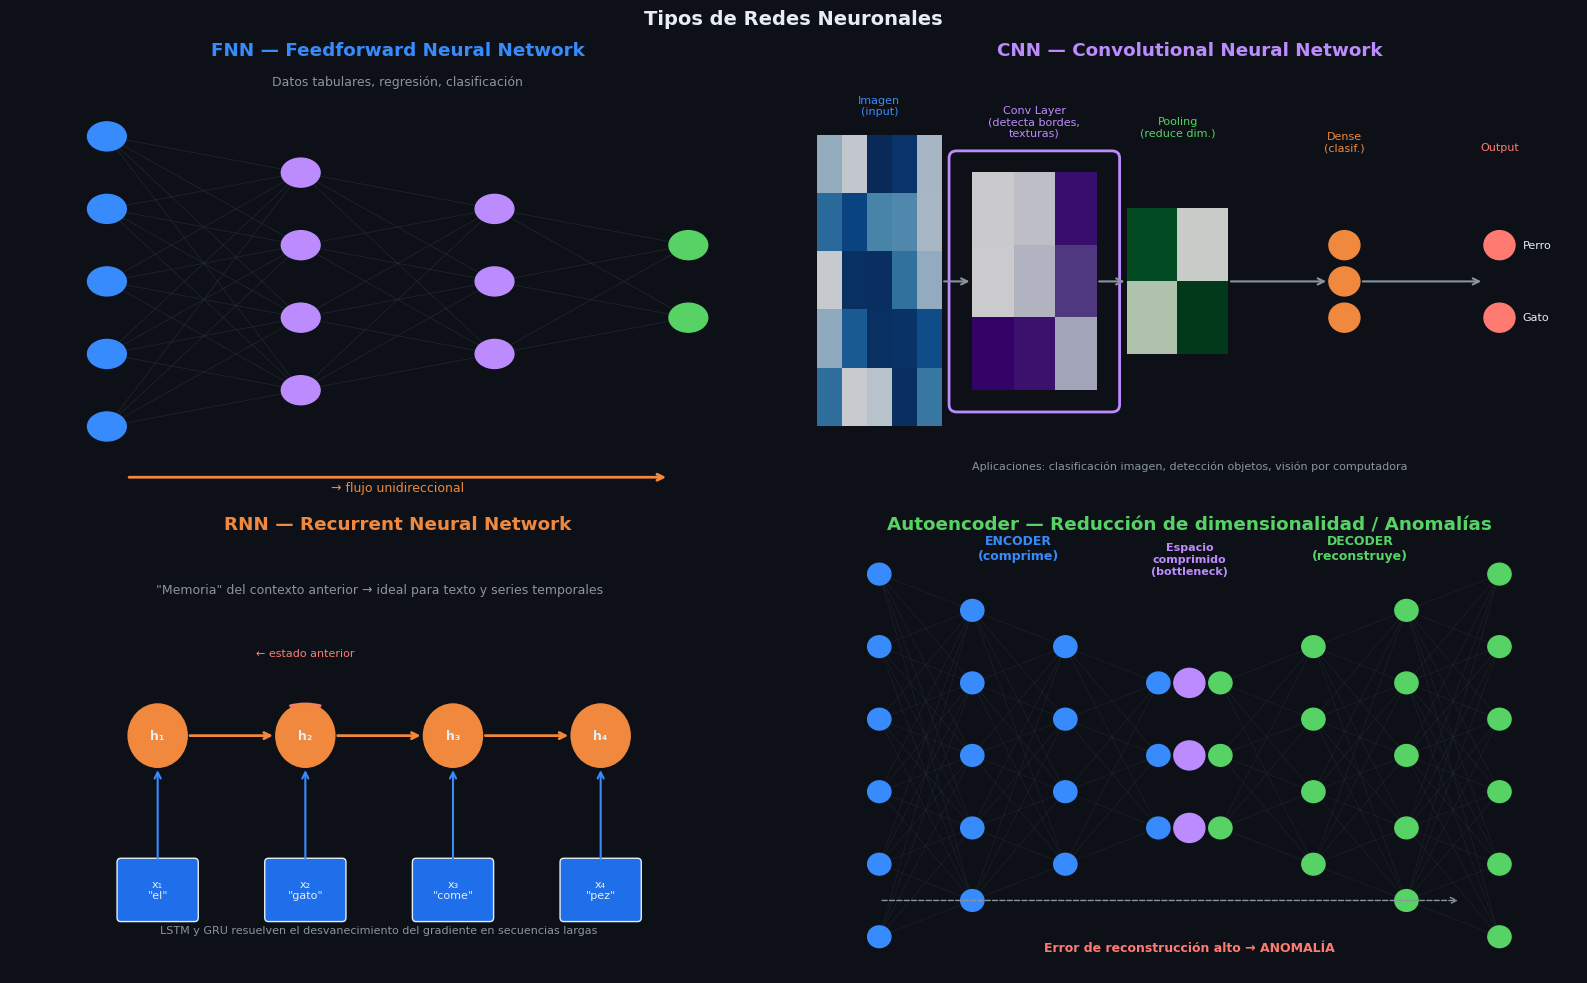

Guardado: 05_tipos_redes.png


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

# --- FNN ---
ax = axes[0]
ax.set_xlim(0, 8)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_title('FNN — Feedforward Neural Network', color=BLUE, fontweight='bold')

layers_fnn = [[1,2,3,4,5], [1.5,2.5,3.5,4.5], [2,3,4], [2.5,3.5]]
xs_fnn = [1, 3, 5, 7]
for l in range(len(layers_fnn)-1):
    for y1 in layers_fnn[l]:
        for y2 in layers_fnn[l+1]:
            ax.plot([xs_fnn[l], xs_fnn[l+1]], [y1, y2], color='#30363d', linewidth=0.5, alpha=0.6)
for lx, ys, color in zip(xs_fnn, layers_fnn, [BLUE, PURPLE, PURPLE, GREEN]):
    for y in ys:
        ax.add_patch(plt.Circle((lx, y), 0.2, color=color, zorder=3))

ax.annotate('', xy=(6.8, 0.3), xytext=(1.2, 0.3),
   arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2))
ax.text(4, 0.1, '→ flujo unidireccional', ha='center', color=ORANGE, fontsize=9)
ax.text(4, 5.7, 'Datos tabulares, regresión, clasificación', ha='center', color=GRAY, fontsize=9)

# --- CNN ---
ax = axes[1]
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_title('CNN — Convolutional Neural Network', color=PURPLE, fontweight='bold')

# Input image block
img = np.random.rand(5, 5)
ax.imshow(img, extent=[0.2, 1.8, 1, 5], cmap='Blues', aspect='auto', alpha=0.8)
ax.text(1, 5.3, 'Imagen\n(input)', ha='center', color=BLUE, fontsize=8)

# Conv layer
conv = np.random.rand(3, 3)
ax.imshow(conv, extent=[2.2, 3.8, 1.5, 4.5], cmap='Purples', aspect='auto', alpha=0.8)
ax.text(3, 5.0, 'Conv Layer\n(detecta bordes,\ntexturas)', ha='center', color=PURPLE, fontsize=8)
ax.add_patch(mpatches.FancyBboxPatch((2.0, 1.3), 1.8+0.2, 3.4,
    boxstyle='round,pad=0.1', facecolor='none', edgecolor=PURPLE, linewidth=2))

# Pooling layer
pool = np.random.rand(2, 2)
ax.imshow(pool, extent=[4.2, 5.5, 2.0, 4.0], cmap='Greens', aspect='auto', alpha=0.8)
ax.text(4.85, 5.0, 'Pooling\n(reduce dim.)', ha='center', color=GREEN, fontsize=8)

# FC
for y in [2.5, 3, 3.5]:
    ax.add_patch(plt.Circle((7, y), 0.2, color=ORANGE, zorder=3))
ax.text(7, 4.8, 'Dense\n(clasif.)', ha='center', color=ORANGE, fontsize=8)

# Output
for y, label in [(2.5,'Gato'), (3.5,'Perro')]:
    ax.add_patch(plt.Circle((9, y), 0.2, color=RED, zorder=3))
    ax.text(9.3, y, label, va='center', color=WHITE, fontsize=8)
ax.text(9, 4.8, 'Output', ha='center', color=RED, fontsize=8)

for x1, x2 in [(1.8, 2.2), (3.8, 4.2), (5.5, 6.8), (7.2, 8.8)]:
    ax.annotate('', xy=(x2, 3), xytext=(x1, 3),
       arrowprops=dict(arrowstyle='->', color=GRAY, lw=1.5))

ax.text(5, 0.4, 'Aplicaciones: clasificación imagen, detección objetos, visión por computadora', 
       ha='center', color=GRAY, fontsize=8)

# --- RNN ---
ax = axes[2]
ax.set_xlim(-0.5, 10)
ax.set_ylim(-0.5, 5)
ax.axis('off')
ax.set_title('RNN — Recurrent Neural Network', color=ORANGE, fontweight='bold')

steps_rnn = ['x₁\n"el"', 'x₂\n"gato"', 'x₃\n"come"', 'x₄\n"pez"']
xs_rnn = [1.5, 3.5, 5.5, 7.5]
hidden_states = ['h₁', 'h₂', 'h₃', 'h₄']

for i, (x, word, h) in enumerate(zip(xs_rnn, steps_rnn, hidden_states)):
    # Input
    ax.add_patch(mpatches.FancyBboxPatch((x-0.5, 0.2), 1, 0.7,
        boxstyle='round,pad=0.05', facecolor='#1f6feb', edgecolor=WHITE, linewidth=1))
    ax.text(x, 0.55, word, ha='center', va='center', color=WHITE, fontsize=8)
    
    # Hidden
    ax.add_patch(plt.Circle((x, 2.5), 0.4, color=ORANGE, zorder=3))
    ax.text(x, 2.5, h, ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold')
    
    # Arrows input→hidden
    ax.annotate('', xy=(x, 2.1), xytext=(x, 0.9),
       arrowprops=dict(arrowstyle='->', color=BLUE, lw=1.5))
    
    # Hidden→hidden (recurrent)
    if i < len(xs_rnn)-1:
        ax.annotate('', xy=(xs_rnn[i+1]-0.4, 2.5), xytext=(x+0.4, 2.5),
           arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2))

# Self-loop on h2
arc = mpatches.Arc((3.5, 2.5), 1.2, 0.8, angle=0, theta1=60, theta2=120, color=RED, linewidth=2)
ax.add_patch(arc)
ax.text(3.5, 3.5, '← estado anterior', ha='center', color=RED, fontsize=8)

ax.text(4.5, 4.3, '"Memoria" del contexto anterior → ideal para texto y series temporales',
       ha='center', color=GRAY, fontsize=9)
ax.text(4.5, 0.0, 'LSTM y GRU resuelven el desvanecimiento del gradiente en secuencias largas',
       ha='center', color=GRAY, fontsize=8)

# --- Autoencoder ---
ax = axes[3]
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')
ax.set_title('Autoencoder — Reducción de dimensionalidad / Anomalías', color=GREEN, fontweight='bold')

enc_layers = [[0.5,1.5,2.5,3.5,4.5,5.5], [1,2,3,4,5], [1.5,2.5,3.5,4.5], [2,3,4]]
dec_layers = [[2,3,4], [1.5,2.5,3.5,4.5], [1,2,3,4,5], [0.5,1.5,2.5,3.5,4.5,5.5]]
enc_xs = [1, 2.2, 3.4, 4.6]
dec_xs = [5.4, 6.6, 7.8, 9]

for layers, xs, color in [(enc_layers, enc_xs, BLUE), (dec_layers, dec_xs, GREEN)]:
    for l in range(len(layers)-1):
        for y1 in layers[l]:
            for y2 in layers[l+1]:
                ax.plot([xs[l], xs[l+1]], [y1, y2], color='#30363d', linewidth=0.4, alpha=0.5)
    for lx, ys in zip(xs, layers):
        for y in ys:
            ax.add_patch(plt.Circle((lx, y), 0.15, color=color, zorder=3))

# Bottleneck
for y in [2, 3, 4]:
    ax.add_patch(plt.Circle((5.0, y), 0.2, color=PURPLE, zorder=4))
ax.text(5, 5.5, 'Espacio\ncomprimido\n(bottleneck)', ha='center', color=PURPLE, fontsize=8, fontweight='bold')

ax.text(2.8, 5.7, 'ENCODER\n(comprime)', ha='center', color=BLUE, fontsize=9, fontweight='bold')
ax.text(7.2, 5.7, 'DECODER\n(reconstruye)', ha='center', color=GREEN, fontsize=9, fontweight='bold')

ax.annotate('', xy=(8.5, 1), xytext=(1, 1),
   arrowprops=dict(arrowstyle='->', color=GRAY, lw=1, linestyle='dashed'))

ax.text(5, 0.3, 'Error de reconstrucción alto → ANOMALÍA', ha='center', color=RED, fontsize=9, fontweight='bold')

plt.suptitle('Tipos de Redes Neuronales', color=WHITE, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUT}/05_tipos_redes.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 05_tipos_redes.png')

## Gráfico 6 — Forward Pass de una neurona (paso a paso numérico)

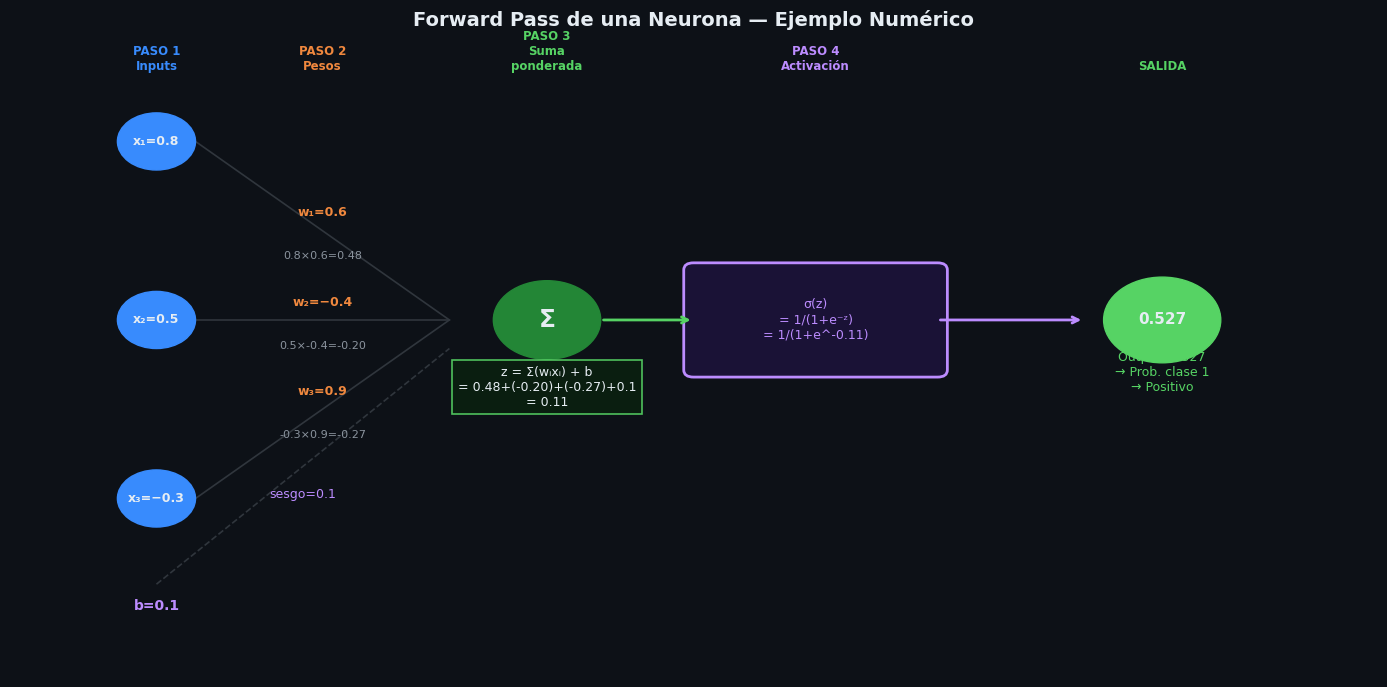

Guardado: 06_forward_pass_neurona.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14)
ax.set_ylim(-1, 8)
ax.axis('off')
ax.set_title('Forward Pass de una Neurona — Ejemplo Numérico', color=WHITE, fontsize=14, fontweight='bold')

# Inputs
inputs  = [('x₁=0.8', 0.8), ('x₂=0.5', 0.5), ('x₃=−0.3', -0.3)]
weights = [('w₁=0.6', 0.6), ('w₂=−0.4', -0.4), ('w₃=0.9', 0.9)]
bias = 0.1
ys = [6.5, 4.0, 1.5]

for i, ((xlabel, xval), (wlabel, wval), y) in enumerate(zip(inputs, weights, ys)):
    # Input node
    ax.add_patch(plt.Circle((1.5, y), 0.4, color=BLUE, zorder=3))
    ax.text(1.5, y, xlabel, ha='center', va='center', color=WHITE, fontsize=9, fontweight='bold')
    
    # Weight on line
    ax.plot([1.9, 4.5], [y, 4.0], color='#30363d', linewidth=1.2)
    ax.text(3.2, (y+4.0)/2+0.2, wlabel, ha='center', color=ORANGE, fontsize=9, fontweight='bold')
    ax.text(3.2, (y+4.0)/2-0.4, f'{xval}×{wval}={xval*wval:.2f}', ha='center', color=GRAY, fontsize=8)

# Bias
ax.text(1.5, 0.0, f'b={bias}', ha='center', va='center', color=PURPLE, fontsize=10, fontweight='bold')
ax.plot([1.5, 4.5], [0.3, 3.6], color='#30363d', linewidth=1.2, linestyle='--')
ax.text(3.0, 1.5, f'sesgo={bias}', ha='center', color=PURPLE, fontsize=9)

# Summation node
z_val = sum(x*w for (_,x),(_,w) in zip(inputs, weights)) + bias
ax.add_patch(plt.Circle((5.5, 4.0), 0.55, color='#238636', zorder=3))
ax.text(5.5, 4.0, 'Σ', ha='center', va='center', color=WHITE, fontsize=18, fontweight='bold')
ax.text(5.5, 2.8, f'z = Σ(wᵢxᵢ) + b\n= {0.8*0.6:.2f}+({0.5*-0.4:.2f})+({-0.3*0.9:.2f})+{bias}\n= {z_val:.2f}',
       ha='center', color=WHITE, fontsize=9,
       bbox=dict(facecolor='#0a2010', edgecolor=GREEN, linewidth=1.2, alpha=0.9))

# Arrow to activation
ax.annotate('', xy=(7.0, 4.0), xytext=(6.05, 4.0),
   arrowprops=dict(arrowstyle='->', color=GREEN, lw=2))

# Activation node
sigma = 1/(1+np.exp(-z_val))
ax.add_patch(mpatches.FancyBboxPatch((7.0, 3.3), 2.5, 1.4,
    boxstyle='round,pad=0.1', facecolor='#1a1236', edgecolor=PURPLE, linewidth=2))
ax.text(8.25, 4.0, f'σ(z)\n= 1/(1+e⁻ᶻ)\n= 1/(1+e^{-z_val:.2f})',
       ha='center', va='center', color=PURPLE, fontsize=9)

# Arrow to output
ax.annotate('', xy=(11.0, 4.0), xytext=(9.5, 4.0),
   arrowprops=dict(arrowstyle='->', color=PURPLE, lw=2))

# Output
ax.add_patch(plt.Circle((11.8, 4.0), 0.6, color=GREEN if sigma > 0.5 else RED, zorder=3))
ax.text(11.8, 4.0, f'{sigma:.3f}', ha='center', va='center', color=WHITE, fontsize=11, fontweight='bold')
ax.text(11.8, 3.0, f'Output: {sigma:.3f}\n→ Prob. clase 1\n→ {"Positivo" if sigma>0.5 else "Negativo"}',
       ha='center', color=GREEN if sigma>0.5 else RED, fontsize=9)

# Step labels
for x, label, color in [(1.5, 'PASO 1\nInputs', BLUE), (3.2, 'PASO 2\nPesos', ORANGE),
                         (5.5, 'PASO 3\nSuma\nponderada', GREEN), (8.25, 'PASO 4\nActivación', PURPLE),
                         (11.8, 'SALIDA', GREEN)]:
    ax.text(x, 7.5, label, ha='center', color=color, fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUT}/06_forward_pass_neurona.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print('Guardado: 06_forward_pass_neurona.png')